# Repetition code under calibrated device noise
Your repetition code, unchanged, plus `noise_from_calibration.CalibratedNoise` (Boston / Kingston / Miami CSVs).
The ideal circuit is built first; noise is added afterwards with `cal.apply(circuit)` (it also strips any noise already in the circuit).

In [1]:
import numpy as np
import pymatching
import stim
from IPython import display

from noise_from_calibration import CalibratedNoise

In [2]:
def repetition_code(distance: int) -> stim.Circuit:
    circuit = stim.Circuit()
    n_qubits = 2 * distance - 1

    # Initialization
    circuit.append("R", range(n_qubits))

    for i in range(1, n_qubits, 2):
        circuit.append("CX", [i - 1, i])
    for i in range(1, n_qubits, 2):
        circuit.append("CX", [i + 1, i])

    circuit.append("MR", range(1, n_qubits, 2))

    for i in range(1, distance):
        circuit.append("DETECTOR", [stim.target_rec(-i)])

    # Error correction rounds
    rnd = stim.Circuit()
    for i in range(1, n_qubits, 2):
        rnd.append("CX", [i - 1, i])
        #rnd.append("DEPOLARIZE2", [i - 1, i], p_cx)      # adding cx error
    rnd.append("TICK")

    for i in range(1, n_qubits, 2):
        rnd.append("CX", [i + 1, i])
        #rnd.append("DEPOLARIZE2", [i + 1, i], p_cx)      # here too
    rnd.append("TICK")

    #rnd.append("X_ERROR", range(1, n_qubits, 2), p_meas)  # adding measurment error
    rnd.append("MR", range(1, n_qubits, 2))
    rnd.append("TICK")

    for i in range(1, distance):
        rnd.append(
            "DETECTOR",
            [stim.target_rec(-i - (distance - 1)), stim.target_rec(-i)],
        )

    circuit += (3 - 1) * rnd

    # Closing the circuit
    circuit.append("M", range(0, n_qubits, 2))

    for i in range(1, distance):
        circuit.append(
            "DETECTOR",
            [
                stim.target_rec(-i),
                stim.target_rec(-i - 1),
                stim.target_rec(-i - distance),
            ],
        )

    circuit.append("OBSERVABLE_INCLUDE", [stim.target_rec(-1)], 0)
    return circuit

## 1. Ideal circuit (no noise): the logical error rate must be 0

In [11]:
def run(circuit: stim.Circuit, shots: int = 1_000_000):
    dem = circuit.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)
    detectors, observables = circuit.compile_detector_sampler().sample(
        shots, separate_observables=True
    )
    predictions = matching.decode_batch(detectors)
    failures = (observables ^ predictions)[:, 0]
    return np.mean(failures), np.mean(1 - 2 * failures.astype(np.int8))


ideal = repetition_code(5)
ler, exp = run(ideal, 1_000_000)
print(f"Logical error rate: {ler}")
print(f"<0|Z|0>_L = {exp}")

Logical error rate: 0.0
<0|Z|0>_L = 1.0


## 2. Add calibrated noise from one device

fake_kingston_qubits: 151 qubits (-5), 169 pairs (-7); median 2q=1.80e-03, readout=9.52e-03, T1=284us, T2=148us


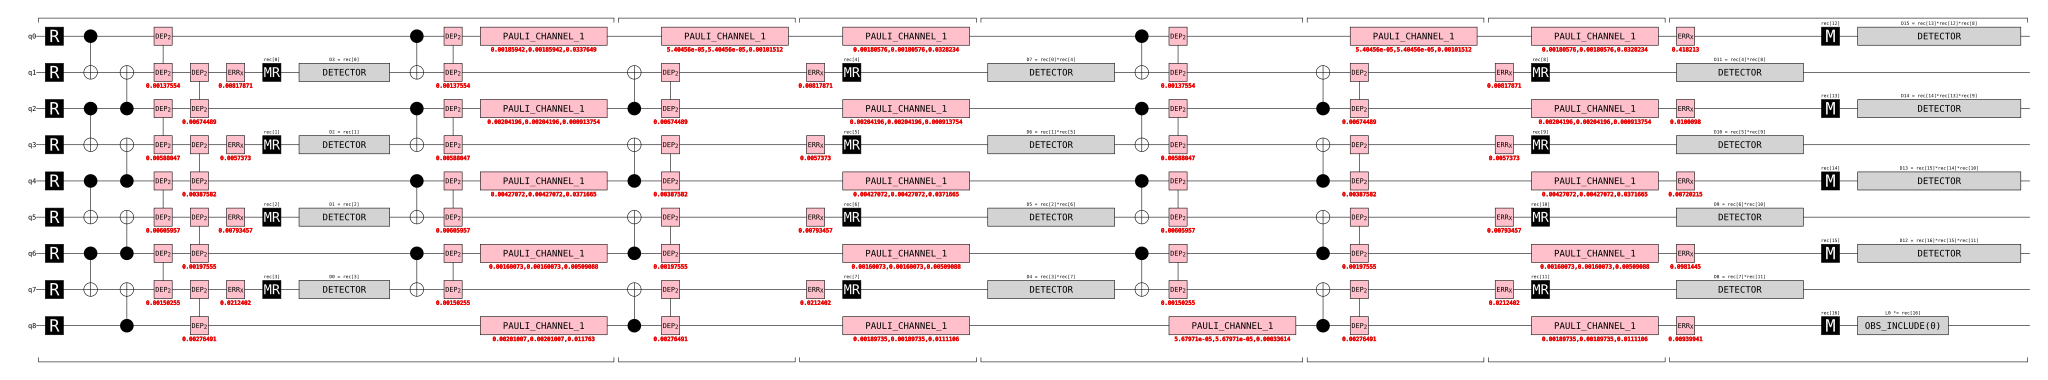

In [12]:
device = "kingston"   # boston | kingston | miami
cal = CalibratedNoise.from_fake(device, seed=0)
print(cal.cal.summary())

circuit = cal.apply(ideal)
circuit.diagram("timeline-svg")

In [13]:
ler, exp = run(circuit, 1_000_000)
print(f"Logical error rate: {ler}")
print(f"<0|Z|0>_L = {exp}")

Logical error rate: 0.001024
<0|Z|0>_L = 0.997952


## 3. Which noise source matters? (ablation)
Each scale is 1.0 = as calibrated, 0.0 = off. Resets are assumed perfect (no preparation error).

In [14]:
rows = [("all on", {})] + [(f"{k} off", {k: 0.0}) for k in
        ("gate1_scale", "gate2_scale", "readout_scale", "idle_scale")]
for label, kw in rows:
    c = CalibratedNoise.from_fake(device, seed=0, **kw).apply(ideal)
    print(f"{label:18s} {run(c, 300_000)[0]:.6f}")

all on             0.001063
gate1_scale off    0.001037
gate2_scale off    0.000763
readout_scale off  0.000023
idle_scale off     0.000420


## 4. Devices x distances (several seeds)
A seed is one random draw of qubits/pairs from the device's calibration data, so use several and look at the spread.

In [15]:
distances = [3, 5, 7, 9]
seeds = range(5)
shots = 200_000

for dev in ["boston", "kingston", "miami"]:
    print(dev)
    for d in distances:
        ideal_d = repetition_code(d)
        r = [run(CalibratedNoise.from_fake(dev, seed=s).apply(ideal_d), shots)[0] for s in seeds]
        print(f"  d={d}: mean={np.mean(r):.5f}  min={np.min(r):.5f}  max={np.max(r):.5f}")

boston
  d=3: mean=0.00164  min=0.00064  max=0.00249
  d=5: mean=0.00016  min=0.00007  max=0.00024
  d=7: mean=0.00001  min=0.00000  max=0.00002
  d=9: mean=0.00000  min=0.00000  max=0.00001
kingston
  d=3: mean=0.00963  min=0.00209  max=0.01973
  d=5: mean=0.00052  min=0.00014  max=0.00099
  d=7: mean=0.00009  min=0.00001  max=0.00034
  d=9: mean=0.00001  min=0.00000  max=0.00003
miami
  d=3: mean=0.00527  min=0.00375  max=0.00944
  d=5: mean=0.00078  min=0.00040  max=0.00187
  d=7: mean=0.00010  min=0.00005  max=0.00020
  d=9: mean=0.00002  min=0.00000  max=0.00003
